# DeepSORT baseline (proposal section 6.0)

This notebook imports DeepSORT, runs it on the validation and test videos (MOT17-11 and MOT17-13) and scores it with
TrackEval, the official MOTChallenge evaluation code. It is the baseline Rowan's model is compared with later.

* **DeepSORT is used as it is:** no code edits, no retraining, no tuning on the test video.
* **DeepSORT sees the original frames** at full size in original pixels. The 1920 × 1088 resize and the mean/std normalization are for Rowan's model only.
* **Scoring uses the unaltered `gt.txt` files** (read-only). Everything is written to `outputs/deepsort/`.
* Run it with **Restart kernel → Run all**. It takes about 15–20 minutes on CPU.

In [1]:
# ---- Imports ----
import configparser                  # reads each video's seqinfo.ini
import hashlib                       # MD5 hashes, to prove the raw data files are not changed
import importlib.metadata            # package version numbers
import time                          # frames per second
import warnings
from pathlib import Path             # file paths that work on Windows, Mac, Linux and Colab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# ---- Paths: built exactly as in the exploratory notebook ----
# Jupyter and VS Code start a notebook inside its own folder, which is MOT17/MOT17/.
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parents[1]            # two folders up from the notebook
DATA_ROOT = PROJECT_ROOT / "MOT17" / "MOT17"      # holds train/ and test/ (read-only)
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
OUTPUT_DATA = OUTPUT_ROOT / "data"                # frames.csv and boxes.csv from the exploratory notebook
DS_OUT = OUTPUT_ROOT / "deepsort"                 # everything this notebook writes goes here
for folder in [DS_OUT / "trackers", DS_OUT / "eval", DS_OUT / "figures", DS_OUT / "repeat"]:
    folder.mkdir(parents=True, exist_ok=True)

assert (DATA_ROOT / "train").is_dir(), f"MOT17 train/ folder not found in {DATA_ROOT}"
assert (OUTPUT_DATA / "frames.csv").is_file(), "Run 'Exploratory data analysis.ipynb' first: frames.csv is missing"

# ---- Settings ----
DETECTOR_COPY = "FRCNN"      # the copy of each video used throughout the project
CONF_THRESHOLD = 0.5         # DECISION B.3: keep supplied detections with confidence >= 0.5
SOURCES = ["frcnn", "gt"]    # Run A = MOT17's Faster R-CNN detections, Run B = ground-truth boxes ("perfect detector")

# DECISION B.4: the original DeepSORT paper's settings, not tuned.
DEEPSORT_SETTINGS = {
    "max_age": 30,                 # delete a track after 30 frames without a match
    "n_init": 3,                   # confirm a track after 3 consecutive matches
    "max_cosine_distance": 0.2,    # largest appearance difference still allowed for a match
    "nn_budget": 100,              # appearance features remembered per track
    "max_iou_distance": 0.7,       # largest box-overlap distance (1 - IoU) still allowed for a match
}

# MD5 fingerprints of the raw files this notebook reads, re-checked at the end to prove nothing changed.
def file_md5(path):
    """MD5 hash of a file's bytes: an unchanged file keeps the same hash."""
    return hashlib.md5(path.read_bytes()).hexdigest()

RAW_FILES = [DATA_ROOT / "train" / f"MOT17-{v}-{DETECTOR_COPY}" / sub for v in ["11", "13"]
             for sub in ["gt/gt.txt", "det/det.txt", "seqinfo.ini"]]
raw_md5_before = {str(p): file_md5(p) for p in RAW_FILES}

report = {}     # section heading -> Markdown text, saved as deepsort_report.md
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DS_OUT:      ", DS_OUT)

PROJECT_ROOT: C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project
DS_OUT:       C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort


In [2]:
# ---- Small helper functions ----

def read_seqinfo(folder):
    """Read a video folder's seqinfo.ini: number of frames and frame size."""
    parser = configparser.ConfigParser()
    parser.read(folder / "seqinfo.ini")
    s = parser["Sequence"]
    return {"seq_length": int(s["seqLength"]), "im_width": int(s["imWidth"]), "im_height": int(s["imHeight"])}


def md_table(df, decimals=1):
    """Turn a DataFrame into a Markdown table for the report (numbers rounded to `decimals` places)."""
    def fmt(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "**NO**"
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        if isinstance(v, (float, np.floating)):
            return f"{v:,.{decimals}f}"
        return str(v)
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    divider = "|" + "|".join(["---"] * len(df.columns)) + "|"
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, divider] + rows)

## B.1 Install DeepSORT and the scoring code
Installs `deep-sort-realtime` (a maintained PyTorch DeepSORT) and TrackEval (the official MOTChallenge scorer) into this notebook's Python, and records their versions.

Two compatibility fixes, agreed with Rowan (neither edits DeepSORT's or TrackEval's code):
* **`setuptools<81`:** `deep-sort-realtime` loads its appearance network with `pkg_resources`, which setuptools removed in version 81.
* **NumPy aliases:** TrackEval still uses `np.float` and `np.int`, which NumPy removed in version 1.24. They were only other names for Python's `float` and `int`, so restoring them changes no result.

In [3]:
# Install into the Python this notebook runs on. Already-installed packages are skipped quickly.
%pip install -q "setuptools<81" deep-sort-realtime git+https://github.com/JonathonLuiten/TrackEval.git

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\nepul\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [4]:
# Record the version of every package that affects the results.
packages = ["deep-sort-realtime", "trackeval", "opencv-python", "torch", "numpy", "setuptools"]
versions = pd.DataFrame({"package": packages, "version": [importlib.metadata.version(p) for p in packages]})
display(versions)

,package,version
0,deep-sort-realtime,1.3.2
1,trackeval,1.0.dev1
2,opencv-python,5.0.0.93
3,torch,2.14.0
4,numpy,2.4.3
5,setuptools,80.10.2


In [5]:
# Fix 2: put back the two names TrackEval still uses. np.float was simply Python's float, np.int was int.
np.float = float
np.int = int

# deep-sort-realtime warns that pkg_resources is deprecated; that's expected (fix 1), so hide just that warning.
warnings.filterwarnings("ignore", message=".*pkg_resources is deprecated.*")

from deep_sort_realtime.deepsort_tracker import DeepSort
import trackeval   # prints a note about BURST/pycocotools: that's a different dataset, not used here

report["B.1 Packages"] = md_table(versions) + (
    "\n\nCompatibility fixes (no package code edited): `setuptools<81` so deep-sort-realtime can load its embedder "
    "with `pkg_resources`; `np.float = float` and `np.int = int` before scoring, because TrackEval still uses these "
    "names, which NumPy 1.24 removed (they were only aliases for the built-ins).")

Error importing BURST due to missing underlying dependency: No module named 'pycocotools'


## B.2 Which videos
DeepSORT is not trained here, so it runs only on the validation and test videos from `frames.csv`: MOT17-11 and MOT17-13. The headline result is MOT17-13, the held-out test video.

In [6]:
# The videos of the validation and test splits, with their length and frame size from seqinfo.ini.
frames = pd.read_csv(OUTPUT_DATA / "frames.csv")
eval_videos = frames[frames["split"].isin(["val", "test"])].groupby("video")["split"].first().reset_index()
eval_videos["folder"] = [DATA_ROOT / "train" / f"{v}-{DETECTOR_COPY}" for v in eval_videos["video"]]
info = pd.DataFrame([read_seqinfo(f) for f in eval_videos["folder"]])
eval_videos = pd.concat([eval_videos, info], axis=1)
VIDEO_INFO = eval_videos.set_index("video")
display(eval_videos[["video", "split", "seq_length", "im_width", "im_height"]])

,video,split,seq_length,im_width,im_height
0,MOT17-11,val,900,1920,1080
1,MOT17-13,test,750,1920,1080


## B.3 What detections DeepSORT receives
DeepSORT doesn't find people itself; it needs boxes for every frame. The box source is one setting:
* **`"frcnn"` (Run A):** MOT17's supplied Faster R-CNN detections (`det/det.txt`), confidence ≥ 0.5.
* **`"gt"` (Run B):** the ground-truth boxes, a "perfect detector". Every error left is a tracking error, so this is an **upper bound**, not a real result. DeepSORT gets only the boxes, never the IDs.
* **`"model"`:** boxes from Rowan's model, for the later fair comparison. Not available yet.

In [7]:
boxes = pd.read_csv(OUTPUT_DATA / "boxes.csv")


def load_detections(source, video):
    """Detections for every frame of a video: {frame: [([left, top, width, height], confidence, "person"), ...]},
    in original pixels. Also returns how many boxes were available and how many are given to DeepSORT."""
    v = VIDEO_INFO.loc[video]
    if source == "frcnn":
        det = pd.read_csv(v["folder"] / "det" / "det.txt", header=None,
                          names=["frame", "id", "left", "top", "width", "height", "conf"])
        available = len(det)
        det = det[det["conf"] >= CONF_THRESHOLD]
    elif source == "gt":
        gt = boxes[boxes["video"] == video]
        available = len(gt)
        # Fractions back to original pixels (the reverse of step 1.6). Identity labels are NOT passed on.
        det = pd.DataFrame({
            "frame": gt["frame"],
            "left": (gt["cx"] - gt["w"] / 2) * v["im_width"],
            "top": (gt["cy"] - gt["h"] / 2) * v["im_height"],
            "width": gt["w"] * v["im_width"],
            "height": gt["h"] * v["im_height"],
            "conf": 1.0,
        })
    elif source == "model":
        raise NotImplementedError("'model' detections are not available yet: Rowan's model doesn't produce boxes yet.")
    else:
        raise ValueError(f"Unknown detection source: {source}")

    # det.txt is not sorted by frame, so group the rows by frame number.
    per_frame = {f: [] for f in range(1, v["seq_length"] + 1)}
    for r in det.itertuples():
        per_frame[int(r.frame)].append(([r.left, r.top, r.width, r.height], float(r.conf), "person"))
    return per_frame, available, len(det)


detection_counts = []
for source in SOURCES:
    for video in VIDEO_INFO.index:
        _, available, given = load_detections(source, video)
        detection_counts.append({"source": source, "video": video, "boxes_available": available, "boxes_given": given,
                                 "given_pct": 100 * given / available})
detection_counts = pd.DataFrame(detection_counts)
display(detection_counts)
print("Expected for frcnn: 5,673 of 6,007 (MOT17-11) and 7,339 of 8,442 (MOT17-13)")

# The "model" source must fail with a clear message for now.
try:
    load_detections("model", "MOT17-13")
except NotImplementedError as error:
    print("model source:", error)

report["B.3 Detections given to DeepSORT"] = (
    f"Run A (`frcnn`): supplied Faster R-CNN detections with confidence >= {CONF_THRESHOLD}. "
    "Run B (`gt`): ground-truth pedestrian boxes from boxes.csv converted back to pixels, confidence 1.0, no IDs.\n\n"
    + md_table(detection_counts))

,source,video,boxes_available,boxes_given,given_pct
0,frcnn,MOT17-11,6007,5673,94.439820
1,frcnn,MOT17-13,8442,7339,86.934376
2,gt,MOT17-11,9436,9436,100.000000
3,gt,MOT17-13,11642,11642,100.000000


Expected for frcnn: 5,673 of 6,007 (MOT17-11) and 7,339 of 8,442 (MOT17-13)
model source: 'model' detections are not available yet: Rowan's model doesn't produce boxes yet.


## B.4 Run DeepSORT
One fresh tracker per video. Frames go in their original order at full size. Each frame's confirmed tracks are written in MOTChallenge format.

In [8]:
def run_deepsort(source, video, out_file):
    """Track one video with a fresh DeepSORT and write its tracks to out_file. Returns frames per second."""
    v = VIDEO_INFO.loc[video]
    detections, _, _ = load_detections(source, video)
    # bgr=False: frames are loaded with PIL, which gives RGB (the package assumes OpenCV's BGR by default).
    # embedder_gpu=False: this computer runs PyTorch on CPU. embedder="mobilenet" is the package's default.
    tracker = DeepSort(**DEEPSORT_SETTINGS, embedder="mobilenet", embedder_gpu=False, bgr=False)

    lines = []
    start = time.time()
    for frame in range(1, v["seq_length"] + 1):                       # original order, never shuffled
        image = np.asarray(Image.open(v["folder"] / "img1" / f"{frame:06d}.jpg").convert("RGB"))  # full size
        tracks = tracker.update_tracks(detections[frame], frame=image)
        for track in tracks:
            # The original DeepSORT's output rule: confirmed tracks that were matched in this frame or the one before.
            if not track.is_confirmed() or track.time_since_update > 1:
                continue
            left, top, width, height = track.to_ltwh()
            # MOTChallenge format: frame, id, left, top, width, height, conf, -1, -1, -1 (conf = 1, as the original writes it)
            lines.append(f"{frame},{int(track.track_id)},{left:.2f},{top:.2f},{width:.2f},{height:.2f},1,-1,-1,-1")
    fps = v["seq_length"] / (time.time() - start)

    out_file.parent.mkdir(parents=True, exist_ok=True)
    out_file.write_text("\n".join(lines) + "\n")
    return fps


def tracker_file(source, video, root=DS_OUT / "trackers"):
    """Where a run's output goes: trackers/DeepSORT_<source>/data/<video>-FRCNN.txt (named like the GT folder)."""
    return root / f"DeepSORT_{source}" / "data" / f"{video}-{DETECTOR_COPY}.txt"

In [9]:
# Run A and Run B on both videos (about 3 minutes per video on CPU).
run_fps = {}
for source in SOURCES:
    for video in VIDEO_INFO.index:
        fps = run_deepsort(source, video, tracker_file(source, video))
        run_fps[(source, video)] = fps
        n_rows = len(tracker_file(source, video).read_text().splitlines())
        print(f"{source:5s} {video}: {VIDEO_INFO.loc[video, 'seq_length']} frames at {fps:.1f} fps (CPU), {n_rows:,} track rows written")

frcnn MOT17-11: 900 frames at 14.8 fps (CPU), 5,597 track rows written


frcnn MOT17-13: 750 frames at 8.7 fps (CPU), 7,248 track rows written


gt    MOT17-11: 900 frames at 9.2 fps (CPU), 9,350 track rows written


gt    MOT17-13: 750 frames at 5.7 fps (CPU), 11,459 track rows written


## B.5 Score with TrackEval
TrackEval's MOTChallenge 2D-box evaluation, reading the ground truth directly from `train/` (read-only). `DO_PREPROC=True` applies MOT17's standard rule: only pedestrians with `use = 1` count, and predictions on distractors (static people, reflections, …) aren't penalised.

In [10]:
def score(trackers_folder, tracker_names, output_folder):
    """Score tracker files with TrackEval (HOTA, CLEAR, Identity) and return one row of results per tracker and video.
    Setting names were checked against trackeval/datasets/mot_challenge_2d_box.py and trackeval/eval.py."""
    eval_config = trackeval.Evaluator.get_default_eval_config()
    eval_config.update({
        "USE_PARALLEL": False,
        "PRINT_CONFIG": False,
        "PRINT_RESULTS": False,
        "TIME_PROGRESS": False,
        "PLOT_CURVES": False,
        "LOG_ON_ERROR": str(output_folder / "error_log.txt"),   # keep TrackEval from writing into its own folder
    })
    dataset_config = trackeval.datasets.MotChallenge2DBox.get_default_dataset_config()
    dataset_config.update({
        "GT_FOLDER": str(DATA_ROOT / "train"),           # unaltered gt.txt files, read-only
        "TRACKERS_FOLDER": str(trackers_folder),
        "TRACKERS_TO_EVAL": tracker_names,
        "OUTPUT_FOLDER": str(output_folder),
        "CLASSES_TO_EVAL": ["pedestrian"],
        "BENCHMARK": "MOT17",
        "SPLIT_TO_EVAL": "train",
        "SKIP_SPLIT_FOL": True,                          # no "MOT17-train" sub-folder in our layout
        "SEQ_INFO": {f"{v}-{DETECTOR_COPY}": None for v in VIDEO_INFO.index},   # None: lengths come from seqinfo.ini
        "TRACKER_SUB_FOLDER": "data",
        "DO_PREPROC": True,
        "PRINT_CONFIG": False,
    })
    metric_config = {"THRESHOLD": 0.5, "PRINT_CONFIG": False}
    metrics = [trackeval.metrics.HOTA(metric_config), trackeval.metrics.CLEAR(metric_config),
               trackeval.metrics.Identity(metric_config)]
    results, messages = trackeval.Evaluator(eval_config).evaluate(
        [trackeval.datasets.MotChallenge2DBox(dataset_config)], metrics)
    assert all(m == "Success" for m in messages["MotChallenge2DBox"].values()), messages

    rows = []
    for name in tracker_names:
        for video in VIDEO_INFO.index:
            r = results["MotChallenge2DBox"][name][f"{video}-{DETECTOR_COPY}"]["pedestrian"]
            rows.append({
                "tracker": name, "video": video,
                "HOTA": 100 * float(r["HOTA"]["HOTA"].mean()),    # HOTA is averaged over its IoU thresholds
                "MOTA": 100 * float(r["CLEAR"]["MOTA"]),
                "IDF1": 100 * float(r["Identity"]["IDF1"]),
                "ID_switches": int(r["CLEAR"]["IDSW"]),
                "false_positives": int(r["CLEAR"]["CLR_FP"]),
                "false_negatives": int(r["CLEAR"]["CLR_FN"]),
            })
    return pd.DataFrame(rows)


scores = score(DS_OUT / "trackers", [f"DeepSORT_{s}" for s in SOURCES], DS_OUT / "eval")
display(scores.round(1))


Evaluating 2 tracker(s) on 2 sequence(s) for 1 class(es) on MotChallenge2DBox dataset using the following metrics: HOTA, CLEAR, Identity, Count


Evaluating DeepSORT_frcnn




Evaluating DeepSORT_gt



,tracker,video,HOTA,MOTA,IDF1,ID_switches,false_positives,false_negatives
0,DeepSORT_frcnn,MOT17-11,52.1,56.7,59.0,27,112,3951
1,DeepSORT_frcnn,MOT17-13,45.4,48.4,54.9,124,745,5139
2,DeepSORT_gt,MOT17-11,93.3,97.9,98.1,0,57,143
3,DeepSORT_gt,MOT17-13,78.8,96.5,80.3,8,108,291


## B.6 Report
Writes `results.csv` (one row per detection source and video) and `deepsort_report.md` to `outputs/deepsort/`.

In [11]:
# results.csv: scores + how many detections DeepSORT was given + speed.
results = scores.copy()
results.insert(0, "source", results.pop("tracker").str.replace("DeepSORT_", "", regex=False))
results = results.merge(detection_counts[["source", "video", "boxes_given"]], on=["source", "video"])
results = results.rename(columns={"boxes_given": "detections_given"})
results["fps"] = [run_fps[(s, v)] for s, v in zip(results["source"], results["video"])]
results = results[["source", "video", "HOTA", "MOTA", "IDF1", "ID_switches", "false_positives", "false_negatives",
                   "detections_given", "fps"]]
results.to_csv(DS_OUT / "results.csv", index=False)
display(results.round(1))

# A few plain-English sentences, built from the numbers.
r = results.set_index(["source", "video"])
a, b = r.loc[("frcnn", "MOT17-13")], r.loc[("gt", "MOT17-13")]
reading = (
    f"On the held-out test video MOT17-13, DeepSORT with the supplied Faster R-CNN detections (Run A) scores "
    f"MOTA {a['MOTA']:.1f}%, IDF1 {a['IDF1']:.1f}% and HOTA {a['HOTA']:.1f}%, with {int(a['ID_switches'])} ID switches. "
    f"Most of its errors are missed people ({int(a['false_negatives']):,} false negatives vs {int(a['false_positives']):,} false positives), "
    f"which mostly reflects the detector and the {CONF_THRESHOLD} confidence threshold rather than the tracking. "
    f"Given perfect boxes (Run B), the same tracker reaches MOTA {b['MOTA']:.1f}% and IDF1 {b['IDF1']:.1f}% "
    f"with {int(b['ID_switches'])} ID switches: this is an upper bound on DeepSORT's tracking with these settings, not a real result, "
    f"because its input is the answer key. The gap between Run A and Run B shows how much of the error comes from detection."
)
print(reading)

settings_table = pd.DataFrame({"setting": list(DEEPSORT_SETTINGS) + ["embedder", "confidence threshold (Run A)", "tracks written"],
                               "value": [str(x) for x in DEEPSORT_SETTINGS.values()]
                                        + ["mobilenet (package default)", str(CONF_THRESHOLD),
                                           "confirmed and time_since_update <= 1"]})
report["B.4 DeepSORT settings"] = "Original DeepSORT paper settings, not tuned.\n\n" + md_table(settings_table)
report["B.6 Results"] = (md_table(results) + "\n\nHOTA, MOTA and IDF1 are percentages; fps is tracking speed on CPU "
                         "(including reading the JPEG frames).\n\n" + reading)
report["Limitations"] = "\n".join([
    "- **Appearance network:** the package's MobileNetV2 trained on ImageNet, not the original paper's person "
    "re-identification network trained on MARS, so appearance matching is weaker than in the paper.",
    f"- **Confidence threshold:** Run A keeps supplied detections with confidence >= {CONF_THRESHOLD}; a different "
    "threshold changes the false positive / false negative balance. It was not tuned.",
    "- **CPU timing:** fps was measured on a CPU and includes loading each JPEG; it is not comparable to published GPU speeds.",
    "- **Run B is an upper bound only:** it is given the ground-truth boxes.",
    "- **Compatibility fixes:** `setuptools<81` and the restored NumPy aliases (see B.1); neither changes any computation.",
    "- **Published DeepSORT-on-MOT17 numbers** use a different detector threshold and appearance network, so they are only a loose guide.",
])


def write_report():
    """Write deepsort_report.md from everything collected in `report`."""
    text = "# DeepSORT baseline report\n\nGenerated by `DeepSORT baseline.ipynb`. Videos: MOT17-11 (validation), MOT17-13 (test, headline).\n\n"
    for heading, body in report.items():
        text += f"## {heading}\n\n{body}\n\n"
    (DS_OUT / "deepsort_report.md").write_text(text, encoding="utf-8")


write_report()
print("Saved", DS_OUT / "results.csv", "and", DS_OUT / "deepsort_report.md")

,source,video,HOTA,MOTA,IDF1,ID_switches,false_positives,false_negatives,detections_given,fps
0,frcnn,MOT17-11,52.1,56.7,59.0,27,112,3951,5673,14.8
1,frcnn,MOT17-13,45.4,48.4,54.9,124,745,5139,7339,8.7
2,gt,MOT17-11,93.3,97.9,98.1,0,57,143,9436,9.2
3,gt,MOT17-13,78.8,96.5,80.3,8,108,291,11642,5.7


On the held-out test video MOT17-13, DeepSORT with the supplied Faster R-CNN detections (Run A) scores MOTA 48.4%, IDF1 54.9% and HOTA 45.4%, with 124 ID switches. Most of its errors are missed people (5,139 false negatives vs 745 false positives), which mostly reflects the detector and the 0.5 confidence threshold rather than the tracking. Given perfect boxes (Run B), the same tracker reaches MOTA 96.5% and IDF1 80.3% with 8 ID switches: this is an upper bound on DeepSORT's tracking with these settings, not a real result, because its input is the answer key. The gap between Run A and Run B shows how much of the error comes from detection.
Saved C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\results.csv and C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\deepsort_report.md


## B.7 Checks
Each check prints PASS or FAIL with the numbers it compared. They are summarised in the last cell.

In [12]:
check_results = []

def check(name, passed, detail):
    """Print and record the result of one check."""
    check_results.append({"check": name, "passed": bool(passed), "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}: {detail}")


TRACK_COLUMNS = ["frame", "id", "left", "top", "width", "height", "conf", "x", "y", "z"]

def read_tracks(path):
    """Read a MOTChallenge tracker file."""
    return pd.read_csv(path, header=None, names=TRACK_COLUMNS)


# Output files are valid: frames in range, IDs positive whole numbers, boxes in original pixels (not 0-1 fractions).
for source in SOURCES:
    for video in VIDEO_INFO.index:
        t = read_tracks(tracker_file(source, video))
        v = VIDEO_INFO.loc[video]
        frames_ok = t["frame"].between(1, v["seq_length"]).all()
        ids_ok = (t["id"] > 0).all() and (t["id"] % 1 == 0).all()
        centre_x = t["left"] + t["width"] / 2
        centre_y = t["top"] + t["height"] / 2
        pixels_ok = ((t["width"] > 1).all() and (t["height"] > 1).all()
                     and centre_x.between(-v["im_width"], 2 * v["im_width"]).all()
                     and centre_y.between(-v["im_height"], 2 * v["im_height"]).all())
        check(f"{source} {video} output file valid", frames_ok and ids_ok and pixels_ok,
              f"{len(t):,} rows, frames {t['frame'].min()}-{t['frame'].max()} (video has {v['seq_length']}), "
              f"{t['id'].nunique()} IDs, median box {t['width'].median():.0f} x {t['height'].median():.0f} px")

# Run B (perfect boxes) should track almost perfectly; Run A should be clearly above 0.
for video in VIDEO_INFO.index:
    mota_b = r.loc[("gt", video), "MOTA"]
    check(f"Run B {video} MOTA above 90%", mota_b > 90, f"MOTA = {mota_b:.1f}%")
    mota_a = r.loc[("frcnn", video), "MOTA"]
    check(f"Run A {video} MOTA clearly above 0", mota_a > 10, f"MOTA = {mota_a:.1f}%")

[PASS] frcnn MOT17-11 output file valid: 5,597 rows, frames 3-900 (video has 900), 60 IDs, median box 159 x 465 px
[PASS] frcnn MOT17-13 output file valid: 7,248 rows, frames 3-750 (video has 750), 96 IDs, median box 32 x 86 px
[PASS] gt MOT17-11 output file valid: 9,350 rows, frames 3-900 (video has 900), 69 IDs, median box 119 x 364 px
[PASS] gt MOT17-13 output file valid: 11,459 rows, frames 3-750 (video has 750), 71 IDs, median box 30 x 85 px
[PASS] Run B MOT17-11 MOTA above 90%: MOTA = 97.9%
[PASS] Run A MOT17-11 MOTA clearly above 0: MOTA = 56.7%
[PASS] Run B MOT17-13 MOTA above 90%: MOTA = 96.5%
[PASS] Run A MOT17-13 MOTA clearly above 0: MOTA = 48.4%


In [13]:
# Spot check: frame 3 of MOT17-13, Run B. (Frame 1 has no output: with n_init=3 a track is first
# confirmed on its 3rd frame, so frame 3 is the first frame with tracks.)
def iou(a, b):
    """Intersection over union of two [left, top, width, height] boxes."""
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / (a[2] * a[3] + b[2] * b[3] - inter)


SPOT_VIDEO, SPOT_FRAME = "MOT17-13", 3
v = VIDEO_INFO.loc[SPOT_VIDEO]
tracks_b = read_tracks(tracker_file("gt", SPOT_VIDEO))
tracks_b = tracks_b[tracks_b["frame"] == SPOT_FRAME]
gt = pd.read_csv(v["folder"] / "gt" / "gt.txt", header=None,
                 names=["frame", "id", "left", "top", "width", "height", "use", "class", "visibility"])
gt = gt[(gt["frame"] == SPOT_FRAME) & (gt["use"] == 1) & (gt["class"] == 1)]
gt_boxes = gt[["left", "top", "width", "height"]].to_numpy()
best_iou = [max(iou(t, g) for g in gt_boxes) for t in tracks_b[["left", "top", "width", "height"]].to_numpy()]
check(f"spot check {SPOT_VIDEO} frame {SPOT_FRAME}: Run B boxes sit on ground-truth boxes",
      len(best_iou) > 0 and min(best_iou) > 0.5,
      f"{len(tracks_b)} confirmed boxes vs {len(gt)} ground-truth boxes; IoU with nearest GT box: "
      f"mean {np.mean(best_iou):.3f}, min {min(best_iou):.3f}")

# Save the spot-check image: ground truth in green, DeepSORT (Run B) in red.
image = Image.open(v["folder"] / "img1" / f"{SPOT_FRAME:06d}.jpg").convert("RGB")
draw = ImageDraw.Draw(image)
for g in gt_boxes:
    draw.rectangle([g[0], g[1], g[0] + g[2], g[1] + g[3]], outline=(0, 255, 0), width=5)
for t in tracks_b.itertuples():
    draw.rectangle([t.left, t.top, t.left + t.width, t.top + t.height], outline=(255, 0, 0), width=2)
image.save(DS_OUT / "figures" / f"spotcheck_{SPOT_VIDEO}_frame{SPOT_FRAME}_runB.jpg", quality=90)

[PASS] spot check MOT17-13 frame 3: Run B boxes sit on ground-truth boxes: 21 confirmed boxes vs 21 ground-truth boxes; IoU with nearest GT box: mean 0.880, min 0.764


In [14]:
# Repeatable: run Run A on MOT17-13 again into a separate folder and compare the two files byte for byte.
repeat_file = tracker_file("frcnn", "MOT17-13", root=DS_OUT / "repeat")
run_deepsort("frcnn", "MOT17-13", repeat_file)
same = repeat_file.read_bytes() == tracker_file("frcnn", "MOT17-13").read_bytes()
check("Run A on MOT17-13 is repeatable", same,
      f"second run {'identical to' if same else 'DIFFERENT from'} the first "
      f"({len(repeat_file.read_text().splitlines()):,} rows)")

# The raw data files this notebook read are unchanged (same MD5 as at the start).
raw_md5_after = {str(p): file_md5(p) for p in RAW_FILES}
check("raw gt.txt, det.txt and seqinfo.ini unchanged", raw_md5_after == raw_md5_before,
      f"{len(RAW_FILES)} files compared by MD5")

[PASS] Run A on MOT17-13 is repeatable: second run identical to the first (7,248 rows)
[PASS] raw gt.txt, det.txt and seqinfo.ini unchanged: 6 files compared by MD5


Longest-lived track: ID 14, frames 3-406 (372 frames written). Frames drawn: [3, 127, 250, 406]
[PASS] visual check figures saved: 4 frames in C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\figures, following ID 14


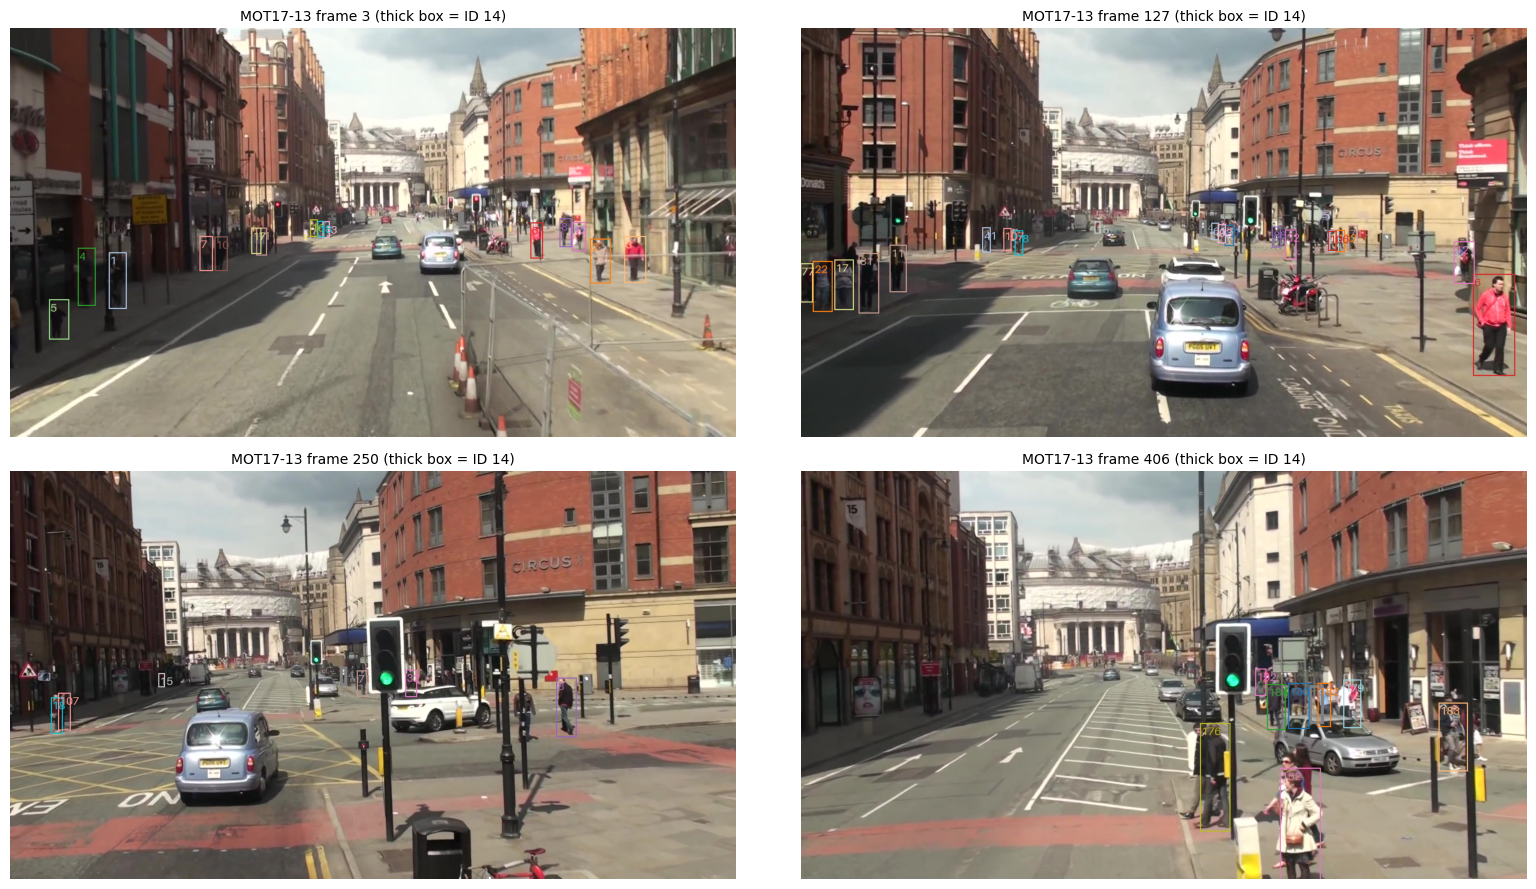

In [15]:
# Visual check: 4 frames of MOT17-13 (Run A), spread across the life of its longest-lived track,
# so the same person keeping the same ID can be seen. Every track is drawn; the long-lived one is thicker.
VIS_VIDEO = "MOT17-13"
v = VIDEO_INFO.loc[VIS_VIDEO]
tracks_a = read_tracks(tracker_file("frcnn", VIS_VIDEO))
lifetime = tracks_a.groupby("id")["frame"].agg(["min", "max", "size"])
lifetime["span"] = lifetime["max"] - lifetime["min"]
focus_id = int(lifetime["span"].idxmax())
focus_frames = tracks_a.loc[tracks_a["id"] == focus_id, "frame"].to_numpy()
picks = [int(focus_frames[i]) for i in np.linspace(0, len(focus_frames) - 1, 4).round().astype(int)]
print(f"Longest-lived track: ID {focus_id}, frames {lifetime.loc[focus_id, 'min']}-{lifetime.loc[focus_id, 'max']} "
      f"({lifetime.loc[focus_id, 'size']} frames written). Frames drawn: {picks}")

font = ImageFont.load_default(size=30)
saved = []
for frame in picks:
    image = Image.open(v["folder"] / "img1" / f"{frame:06d}.jpg").convert("RGB")
    draw = ImageDraw.Draw(image)
    for t in tracks_a[tracks_a["frame"] == frame].itertuples():
        colour = tuple(int(255 * c) for c in plt.cm.tab20(t.id % 20)[:3])    # same colour for the same ID
        draw.rectangle([t.left, t.top, t.left + t.width, t.top + t.height], outline=colour,
                       width=8 if t.id == focus_id else 3)
        draw.text((t.left + 4, t.top + 2), str(t.id), fill=colour, font=font)
    path = DS_OUT / "figures" / f"runA_{VIS_VIDEO}_frame{frame:06d}.jpg"
    image.save(path, quality=90)
    saved.append((frame, image))
check("visual check figures saved", len(saved) == 4, f"{len(saved)} frames in {DS_OUT / 'figures'}, following ID {focus_id}")

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (frame, image) in zip(axes.flat, saved):
    ax.imshow(image)
    ax.set_title(f"{VIS_VIDEO} frame {frame} (thick box = ID {focus_id})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Summary

In [16]:
# Add the checks to the report and print the results table.
checks_table = pd.DataFrame(check_results)
report["B.7 Checks"] = (f"{checks_table['passed'].sum()} of {len(checks_table)} checks passed.\n\n"
                        + md_table(checks_table))
write_report()

print(f"Checks passed: {checks_table['passed'].sum()} / {len(checks_table)}")
for row in checks_table[~checks_table["passed"]].itertuples():
    print("  FAILED:", row.check, "-", row.detail)
print()
print("DeepSORT baseline results (HOTA, MOTA, IDF1 in %; Run B = 'gt' is an upper bound only):")
print(results.round(1).to_string(index=False))

Checks passed: 12 / 12

DeepSORT baseline results (HOTA, MOTA, IDF1 in %; Run B = 'gt' is an upper bound only):
source    video  HOTA  MOTA  IDF1  ID_switches  false_positives  false_negatives  detections_given  fps
 frcnn MOT17-11  52.1  56.7  59.0           27              112             3951              5673 14.8
 frcnn MOT17-13  45.4  48.4  54.9          124              745             5139              7339  8.7
    gt MOT17-11  93.3  97.9  98.1            0               57              143              9436  9.2
    gt MOT17-13  78.8  96.5  80.3            8              108              291             11642  5.7
